In [1]:
!pip install scienceplots
!pip install pint


import numpy as np
import scipy as sp
from scipy.fft import fft2
from scipy.fft import ifft2
from scipy.fft import fftfreq
from scipy.fft import fftshift
import imageio
import cv2

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import animation
from matplotlib.animation import PillowWriter
import pint
import scienceplots

plt.style.use(['science', 'notebook'])
u = pint.UnitRegistry()


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 307.5/307.5 kB 3.4 MB/s eta 0:00:00


#Whole Algo

In [2]:
import numpy as np
from numpy.fft import fft2, ifft2, fftfreq


import numpy as np
from numpy.fft import fft2, ifft2, fftfreq

def propagate_ASM(U0, dx, lam, z):
    """
    Angular spectrum propagation implemented in the same style as your compute_U.

    Uses:
      U(x,y,z) = IFFT2{ FFT2(U0) * exp(i z kz) }
      kz = sqrt(k^2 - kx^2 - ky^2)

    Notes:
    - We compute kz as complex so negative arguments become evanescent (imaginary kz).
    - To avoid exponential blow-up when z<0, we drop evanescent components on back-prop.
    """
    N = U0.shape[0]
    A = fft2(U0)

    kx = 2*np.pi * fftfreq(N, d=dx)
    kxv, kyv = np.meshgrid(kx, kx, indexing="xy")

    k = 2*np.pi / lam
    k_perp2 = kxv**2 + kyv**2

    kz = np.sqrt(np.maximum(0.0, k**2 - k_perp2)) \
         + 1j*np.sqrt(np.maximum(0.0, k_perp2 - k**2))

    if z < 0:
        kz = np.real(kz)  # remove evanescent on back-propagation

    return ifft2(A * np.exp(1j * z * kz))



def apply_hologram(p_in, T, Zt, Zh, Zm, kh, km):
    """
    Your thin acoustic hologram (1D transmission-line model).
    """
    alpha_T = (
        4 * Zt * Zh**2 * Zm
        /
        (
            Zh**2 * (Zt + Zm)**2 * np.cos(kh*T)**2
            +
            (Zh**2 + Zt*Zm)**2 * np.sin(kh*T)**2
        )
    )

    H = np.sqrt(alpha_T) * np.exp(1j * (km - kh) * T)
    return H * p_in


def design_hologram_single_plane(
    p0_amp,
    target_at_z,
    z_target,
    dx,
    lam_m,
    Zt, Zh, Zm,
    kh, km,
    n_iter=1000,
    enforce="amplitude",   # "amplitude" or "complex"
    Tmax=None,
    seed=0.005,
):
    """
    Iterative design of thickness map T(x,y) for ONE image plane.

    Parameters
    ----------
    p0_amp : (N,N) float ndarray
        Transducer amplitude field at hologram input plane (before hologram).
    target_at_z : (N,N) ndarray
        If enforce="amplitude": target magnitude (real, >=0).
        If enforce="complex": target complex pressure.
    z_target : float
        Distance from hologram exit plane to image plane in the MEDIUM.
    dx : float
        Grid spacing.
    lam_m : float
        Wavelength in the medium used for propagation.
    Zt, Zh, Zm, kh, km : floats
        As in apply_hologram.
    n_iter : int
        Number of iterations.
    enforce : str
        "amplitude" or "complex".
    Tmax : float or None
        Optional clamp on thickness (meters).
    seed : int
        RNG seed for initial phase.

    Returns
    -------
    T : (N,N) float ndarray
        Thickness map (meters).
    history : dict
        Simple metrics per iteration.
    """
    rng = np.random.default_rng(seed)
    N = p0_amp.shape[0]

    # Fixed input field from transducer: amplitude given, phase can start random
    p_in = p0_amp * np.exp(1j * 2*np.pi * 0*rng.random((N, N)))

    # Start thickness map
    T = np.zeros_like(p0_amp, dtype=float)+Tmax

    # Precompute target amplitude if needed
    if enforce == "amplitude":
        A_tgt = np.asarray(target_at_z, dtype=float)
    elif enforce == "complex":
        P_tgt = np.asarray(target_at_z, dtype=np.complex128)
        A_tgt = np.abs(P_tgt)
    else:
        raise ValueError("enforce must be 'amplitude' or 'complex'")

    eps = 1e-12
    history = {"amp_mse": [], "amp_corr": []}

    for it in range(n_iter):
        # (1) apply hologram to get field just AFTER hologram (exit side)
        p_exit = apply_hologram(p_in, T, Zt, Zh, Zm, kh, km)

        # (2) forward propagate to image plane
        p_img = propagate_ASM(p_exit, dx=dx, lam=lam_m, z=z_target)

        # (2) evaluate quality (simple metrics)
        A = np.abs(p_img)
        mse = np.mean((A - A_tgt)**2)
        # correlation (avoid all-zeros)
        num = np.sum((A - A.mean()) * (A_tgt - A_tgt.mean()))
        den = np.sqrt(np.sum((A - A.mean())**2) * np.sum((A_tgt - A_tgt.mean())**2) + eps)
        corr = float(num / (den + eps))
        history["amp_mse"].append(float(mse))
        history["amp_corr"].append(corr)

        # (3) enforce image-plane constraint ("reset")
        if enforce == "amplitude":
            p_img = A_tgt * np.exp(1j * np.angle(p_img))
        else:  # enforce == "complex"
            p_img = P_tgt

        # (4) back propagate to hologram exit plane
        p_exit_back = propagate_ASM(p_img, dx=dx, lam=lam_m, z=-z_target)

        # (6/7) update thickness map T so that hologram transfer H matches required phase
        # Required transfer at each pixel: H_req ≈ p_exit_back / p_in
        H_req = p_exit_back / (p_in + eps)

        # Phase-only thickness update (robust + cheap):
        # H(T) has phase (km - kh)T, so set T from angle(H_req) modulo 2π
        dK = (km - kh)
        phase = np.angle(H_req)
        T = (np.mod(phase, 2*np.pi)) / (dK + eps)

        # Optional thickness clamp
        #if Tmax is not None:
            #T = np.clip(T, 0.0, Tmax)

        # (Optional but common) reset p_in phase each iteration or keep it fixed real:
        # If you truly have a known transducer phase, set it here. Otherwise, keep current.
        # p_in = p0_amp  # uncomment if you want strictly real input each iteration

    return T, history

import numpy as np
from matplotlib.textpath import TextPath
from matplotlib.font_manager import FontProperties

def make_letter_target(letter="W", N=256, margin=0.15, weight="bold", blur_sigma_pix=1.2):
    """
    Make an NxN amplitude target image of a letter using matplotlib's vector text.
    Returns a float array in [0,1].
    """
    # Vector outline of the letter
    fp = FontProperties(family="DejaVu Sans", weight=weight)
    tp = TextPath((0, 0), letter, size=1.0, prop=fp)
    bb = tp.get_extents()

    # Normalized grid in [-1,1]x[-1,1]
    xn = np.linspace(-1, 1, N)
    yn = np.linspace(-1, 1, N)
    Xn, Yn = np.meshgrid(xn, yn, indexing="xy")

    # Map normalized grid into the letter's bounding box, leaving a margin
    w = bb.width * (1 - 2*margin)
    h = bb.height * (1 - 2*margin)
    X = bb.x0 + bb.width*margin + (Xn + 1) * 0.5 * w
    Y = bb.y0 + bb.height*margin + (Yn + 1) * 0.5 * h

    pts = np.c_[X.ravel(), Y.ravel()]
    mask = tp.contains_points(pts).reshape(N, N).astype(float)

    # Tiny Gaussian blur (separable) to reduce ringing / hard edges
    if blur_sigma_pix is not None and blur_sigma_pix > 0:
        r = int(np.ceil(3 * blur_sigma_pix))
        t = np.arange(-r, r+1)
        k = np.exp(-0.5 * (t / blur_sigma_pix)**2)
        k /= k.sum()

        # separable convolution
        mask = np.apply_along_axis(lambda m: np.convolve(m, k, mode="same"), 0, mask)
        mask = np.apply_along_axis(lambda m: np.convolve(m, k, mode="same"), 1, mask)

    # Normalize to [0,1]
    mask -= mask.min()
    mask /= (mask.max() + 1e-12)
    return mask

# ------------------------- Minimal usage example -------------------------
if __name__ == "__main__":
    # Grid
    N = 256
    L = 0.04                 # 4 cm aperture width
    dx = L / N
    x = (np.arange(N) - N/2) * dx
    xv, yv = np.meshgrid(x, x, indexing="xy")

    # Medium wave
    f = 20e6                 # 40 kHz ultrasound
    c_m = 1500        # m/s in water (example)
    lam_m = c_m / f
    km = 2*np.pi / lam_m

    # Hologram material wave (example)
    c_h = 2400.0
    lam_h = c_h / f
    kh = 2*np.pi / lam_h

    # Impedances (example numbers; replace with yours)
    rho_m, rho_h, rho_t = 1000.0, 1200.0, 7800.0
    Zm, Zh, Zt = rho_m*c_m, rho_h*c_h, rho_t*5900.0  # transducer c ~ 5900 m/s placeholder

    # Known transducer amplitude at hologram input plane
    # Example: flat-top with apodization
    r = np.sqrt(xv**2 + yv**2)
    p0_amp = np.exp(-(r/0.015)**8)

    S = 4e-3
    D = 0.25e-3

    #target_amp = (np.abs(xv-S/2)< D/2) * (np.abs(yv)<10e-3) + (np.abs(xv+S/2)< D/2) * (np.abs(yv)<10e-3)
    # Target at z: make a focused Gaussian spot (amplitude-only target)
    target_amp = make_letter_target("W", N=N, margin=-0.3, blur_sigma_pix=1.4)

    z_target = 0.15
    #target_amp = np.exp(-((xv/0.004)**2 + (yv/0.002)**2))

    T, hist = design_hologram_single_plane(
        p0_amp=p0_amp,
        target_at_z=target_amp,
        z_target=z_target,
        dx=dx,
        lam_m=lam_m,
        Zt=Zt, Zh=Zh, Zm=Zm,
        kh=kh, km=km,
        n_iter=300,
        enforce="amplitude",
        Tmax=3e-3,   # 3 mm thickness cap, optional
        seed=1 ,
    )

    print("Final amp MSE:", hist["amp_mse"][-1], "Final amp corr:", hist["amp_corr"][-1])





Final amp MSE: 0.04165765358710667 Final amp corr: 0.9768403592174864


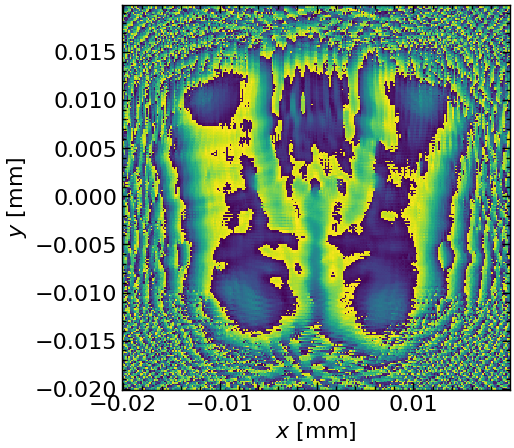

In [7]:

p0_amp = np.exp(-(r/0.015)**8)
p_in = p0_amp

    # Apply hologram (field just after hologram)
p_exit = apply_hologram(p_in, T, Zt, Zh, Zm, kh, km)

    # Propagate to image plane
p_img = propagate_ASM(p_exit, dx=dx, lam=lam_m, z=0.15)


#target_amp = make_letter_target("W", N=N, margin=-0.3, blur_sigma_pix=1.4)

plt.figure(figsize=(5,5))
plt.pcolormesh(xv,yv,np.abs(T) )

plt.xlabel('$x$ [mm]')
plt.ylabel('$y$ [mm]')
plt.show()

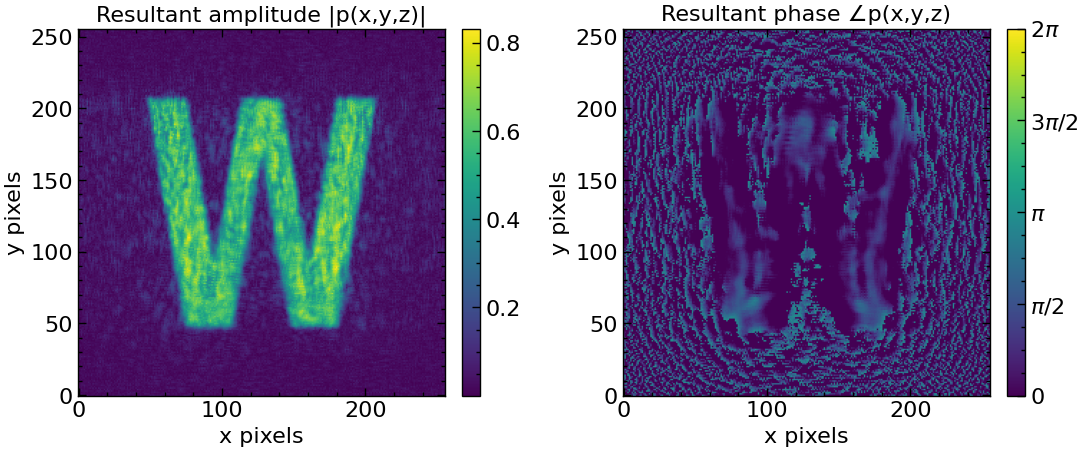

In [9]:
import numpy as np
import matplotlib.pyplot as plt


def plot_result_image(p0_amp, T, dx, lam_m, z_target, Zt, Zh, Zm, kh, km, seed=0):
    """
    Plot the resultant field at the target image plane after applying hologram T.

    Produces:
      - amplitude |p(x,y,z_target)|
      - phase angle(p(x,y,z_target))
    """
    rng = np.random.default_rng(seed)

    # Build an input complex field at hologram input plane
    # (If you know the true transducer phase, replace this random phase with it.)
    p_in = p0_amp * np.exp(1j * 2*np.pi *0* rng.random(p0_amp.shape))

    # Apply hologram (field just after hologram)
    p_exit = apply_hologram(p_in, T, Zt, Zh, Zm, kh, km)

    # Propagate to image plane
    p_img = propagate_ASM(p_exit, dx=dx, lam=lam_m, z=z_target)

    amp = np.abs(p_img)
    phs = np.angle(p_img)

    # Plot
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)

    im0 = axs[0].imshow(amp, origin="lower" )
    axs[0].set_title("Resultant amplitude |p(x,y,z)|")
    axs[0].set_xlabel("x pixels")
    axs[0].set_ylabel("y pixels")
    plt.colorbar(im0, ax=axs[0], fraction=0.046, pad=0.04)

    im1 = axs[1].imshow(phs, origin="lower", vmin=0, vmax=2*np.pi)
    axs[1].set_title("Resultant phase ∠p(x,y,z)")
    axs[1].set_xlabel("x pixels")
    axs[1].set_ylabel("y pixels")
    cb = plt.colorbar(im1, ax=axs[1], fraction=0.046, pad=0.04)
    cb.set_ticks([  0, np.pi/2, np.pi,3/2*np.pi,2*np.pi])
    cb.set_ticklabels([r"$0$", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"])

    plt.show()

    return p_img  # return complex field if you want to compare to target


# Example usage (after your design loop):
p_img = plot_result_image(p0_amp, T, dx, lam_m , z_target, Zt, Zh, Zm, kh, km, seed=1)


=== propagate_ASM sanity checks ===
Finite values OK: True
Round-trip relative RMS error: 5.164e-16
Relative RMS(norm) change after forward propagation: 1.238e-16


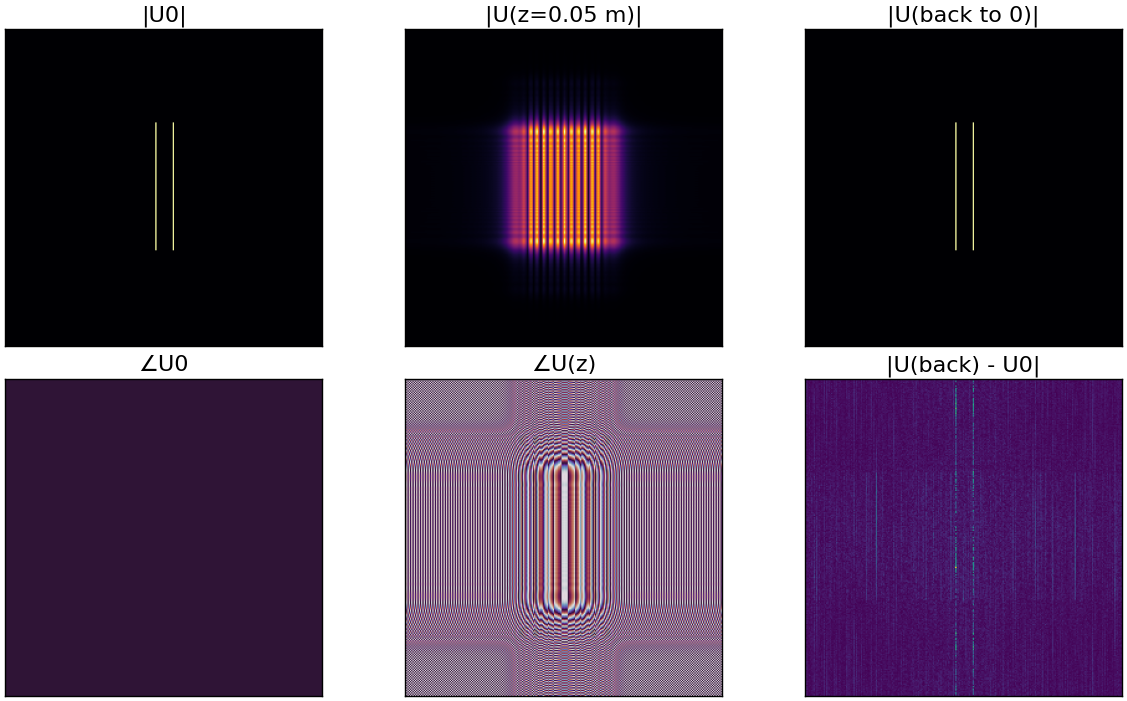

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import fft2, ifft2, fftfreq


def propagate_ASM(U0, dx, lam, z):
    N = U0.shape[0]
    k = 2 * np.pi / lam

    kx = 2 * np.pi * fftfreq(N, d=dx)
    ky = 2 * np.pi * fftfreq(N, d=dx)
    kxv, kyv = np.meshgrid(kx, ky, indexing="xy")

    k_perp2 = kxv**2 + kyv**2

    # Propagating mask (evanescent removed)
    mask = k_perp2 <= k**2

    kz = np.zeros_like(kxv, dtype=np.float64)
    kz[mask] = np.sqrt(k**2 - k_perp2[mask])

    H = np.zeros_like(kxv, dtype=np.complex128)
    H[mask] = np.exp(1j * z * kz[mask])

    return ifft2(fft2(U0) * H)


def rms(x):
    return np.sqrt(np.mean(np.abs(x)**2))


def check_propagate_ASM():
    # ------------------- Setup grid -------------------
    N = 256
    L = 0.04          # 4 cm window
    dx = L / N
    x = (np.arange(N) - N/2) * dx
    xv, yv = np.meshgrid(x, x, indexing="xy")

    # ------------------- Wave params -------------------
    f = 40e6          # 40 kHz
    c = 1500.0        # m/s (water)
    lam = c / f
    z = 0.05          # 5 cm

    # ------------------- Test field (circular super-Gaussian) -------------------
    r = np.sqrt(xv**2 + yv**2)
    S = 2.2e-3
    D = 0.25e-3

    U0 = (np.abs(xv-S/2)< D/2) * (np.abs(yv)<8e-3) + (np.abs(xv+S/2)< D/2) * (np.abs(yv)<8e-3)

    # ------------------- 1) Round-trip stability test -------------------
    Uz = propagate_ASM(U0, dx=dx, lam=lam, z=z)
    Urt = propagate_ASM(Uz, dx=dx, lam=lam, z=-z)

    rel_err_rt = rms(Urt - U0) / (rms(U0) + 1e-12)

    # ------------------- 2) Energy (L2 norm) preservation test -------------------
    # With evanescent removed, the propagating part should be roughly norm-preserving
    norm0 = rms(U0)
    normz = rms(Uz)
    rel_norm_change = (normz - norm0) / (norm0 + 1e-12)

    # ------------------- 3) NaN/Inf check -------------------
    finite_ok = np.isfinite(Uz).all() and np.isfinite(Urt).all()

    print("=== propagate_ASM sanity checks ===")
    print(f"Finite values OK: {finite_ok}")
    print(f"Round-trip relative RMS error: {rel_err_rt:.3e}")
    print(f"Relative RMS(norm) change after forward propagation: {rel_norm_change:.3e}")

    # ------------------- Visualise -------------------
    fig, axs = plt.subplots(2, 3, figsize=(12, 7), constrained_layout=True)

    axs[0, 0].imshow(np.abs(U0), origin="lower", cmap="inferno")
    axs[0, 0].set_title("|U0|")

    axs[0, 1].imshow(np.abs(Uz), origin="lower", cmap="inferno")
    axs[0, 1].set_title(f"|U(z={z} m)|")

    axs[0, 2].imshow(np.abs(Urt), origin="lower", cmap="inferno")
    axs[0, 2].set_title("|U(back to 0)|")

    axs[1, 0].imshow(np.angle(U0), origin="lower", cmap="twilight", vmin=-np.pi, vmax=np.pi)
    axs[1, 0].set_title("∠U0")

    axs[1, 1].imshow(np.angle(Uz), origin="lower", cmap="twilight", vmin=-np.pi, vmax=np.pi)
    axs[1, 1].set_title("∠U(z)")

    axs[1, 2].imshow(np.abs(Urt - U0), origin="lower", cmap="viridis")
    axs[1, 2].set_title("|U(back) - U0|")

    for ax in axs.ravel():
        ax.set_xticks([])
        ax.set_yticks([])

    plt.show()

    # Helpful assert-style checks (tune thresholds if needed)
    # Round-trip won't be machine-zero because evanescent content is discarded
    # but should be "small" for smooth fields and reasonable z.
    if not finite_ok:
        raise RuntimeError("propagate_ASM produced NaN/Inf.")
    if rel_err_rt > 5e-2:
        print("WARNING: Round-trip error is quite large. "
              "This can happen if your field has strong high-k content "
              "or if dx is too large (undersampling).")


if __name__ == "__main__":
    check_propagate_ASM()
